In [237]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


%matplotlib inline

In [238]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
) # Validation

In [239]:
import pandas as pd

# Load datasets cleanly in their rawest forms
train = pd.read_csv("train.csv")
econ = pd.read_csv("economic_indicators.csv")

In [240]:
# Clean headers and initial indicators cleanly before any merging
train.columns = train.columns.str.lower().str.replace(" ", "_", regex=False)
econ.columns = econ.columns.str.lower().str.replace(" ", "_", regex=False)

train.rename(columns={'country_id': 'country'}, inplace=True)
for col in ["country", "loan_type", "new_versus_repeat"]:
    if col in train.columns:
        train[col] = train[col].astype(str).str.lower().str.replace(" ", "_", regex=False)

for cat in ["country", "indicator"]:
    if cat in econ.columns:
        econ[cat] = econ[cat].astype(str).str.lower().str.replace(" ", "_", regex=False)

In [241]:
# Prepare econ for merging
# Identify year columns
year_cols = [col for col in econ.columns if col.startswith('yr')]

# Convert wide to long format
econ_long = econ.melt(
    id_vars=['country', 'indicator'],
    value_vars=year_cols,
    var_name='year',
    value_name='economic_value'
)

# Extract numeric year
econ_long['year'] = econ_long['year'].str.replace('yr', '').astype(int)

# Pivot economic indicators into columns
econ_wide = econ_long.pivot_table(
    index=['country', 'year'],
    columns='indicator',
    values='economic_value',
    aggfunc='first'
).reset_index()

# Remove the columns index name
econ_wide.columns.name = None

In [242]:

# Define categorical and numerical columns

# Categorical features
categorical_cols = [
    'country',
    'loan_type',
    'new_versus_repeat',
]
# Add lender_id only if you want to test its predictive value
# categorical_cols.append('lender_id')
categorical_cols = [
    col for col in categorical_cols
    if col in combined.columns
]
# Exclude target and identifier columns from numerical features
exclude_cols = [
    'target',
    'id',
    'customer_id',
    'tbl_loan_id',
    'lender_id',
    'duration',# use the log variant
    'total_amount', # use the log variant
    'average_precipitation_in_depth_(mm_per_year)', # produce NaN and have a low correlation to target
    'fossil_fuel_energy_consumption_(%_of_total)', # produce NaN and have a low correlation to target
]


numerical_cols = [
    col for col in combined.select_dtypes(include='number').columns
    if col not in exclude_cols
]
print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)


Categorical features: ['country', 'loan_type', 'new_versus_repeat']
Numerical features: ['total_amount_to_repay', 'amount_funded_by_lender', 'lender_portion_funded', 'lender_portion_to_be_repaid', 'loan_year', 'loan_month', 'interest_amount', 'repayment_ratio', 'duration_log', 'total_amount_log', 'deposit_interest_rate_(%)', 'inflation,_consumer_prices_(annual_%)', 'interest_rate_spread_(lending_rate_minus_deposit_rate,_%)', 'lending_interest_rate_(%)', 'official_exchange_rate_(lcu_per_us$,_period_average)', 'real_interest_rate_(%)', 'unemployment_rate']


In [243]:
# mutual_info_score test for categorical columns with respect to the target variable
from sklearn.metrics import mutual_info_score

def mutual_info_target_score(series):
    return mutual_info_score(series, train.target)

mi = train[categorical_cols].apply(mutual_info_target_score)
mi.sort_values(ascending=False)
# print(f"mutual info score:\n {mi}\n")
print("Mutual information for categorical columns with respect to target")
print("-------------------------------------------------------------------")
print(mi.sort_values(ascending=False))
print()


# Pearson co-relation test for numerical columns with respect to the target variable
ans = {}
for column in numerical_cols:
    corr = combined[column].corr(combined['target'])
    key = f"{column}"
    ans[key] = corr
# print(f"numerical_columns correlation to target:\n {ans}\n")
print("Pearson correlation for numerical columns with respect to target")
print("-----------------------------------------------------------------")
print(pd.Series(ans).sort_values(ascending=False))

Mutual information for categorical columns with respect to target
-------------------------------------------------------------------
loan_type            0.015103
new_versus_repeat    0.002525
country              0.000000
dtype: float64

Pearson correlation for numerical columns with respect to target
-----------------------------------------------------------------
repayment_ratio                                              0.650195
duration_log                                                 0.215595
real_interest_rate_(%)                                       0.136682
loan_year                                                    0.125402
lender_portion_to_be_repaid                                  0.110728
lending_interest_rate_(%)                                    0.105480
deposit_interest_rate_(%)                                    0.105103
amount_funded_by_lender                                      0.103777
official_exchange_rate_(lcu_per_us$,_period_average)         0.102569

In [244]:
from sklearn.model_selection import train_test_split

# Split features and labels directly from the cleaned raw train dataset
X_raw = train.drop(columns=['target'])
y_raw = train['target'].values

# Holdout test set creation (20% of dataset)
X_raw_full_train, X_raw_test, y_full_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=1, stratify=y_raw
)

# Split remaining 80% to 60% Train, 20% Validation
X_raw_train, X_raw_val, y_train, y_val = train_test_split(
    X_raw_full_train, y_full_train, test_size=0.25, random_state=1, stratify=y_full_train
)

In [245]:
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import OneHotEncoder, StandardScaler
# from sklearn.impute import SimpleImputer


# # Create preprocessing pipelines
# # Numerical preprocessing
# numerical_pipeline = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler', StandardScaler()),
# ])
# # Categorical preprocessing
# categorical_pipeline = Pipeline([
#     ('imputer', SimpleImputer(strategy='most_frequent')),
#     ('onehot', OneHotEncoder(handle_unknown='ignore')),
# ])
# # Combine the pipelines
# preprocessor = ColumnTransformer([
#     ('numerical', numerical_pipeline, numerical_cols),
#     ('categorical', categorical_pipeline, categorical_cols),
# ])


In [246]:
from sklearn.base import BaseEstimator, TransformerMixin

class CreditFeatureExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, econ_wide_df):
        self.econ_wide_df = econ_wide_df

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        X_out = X.copy()

        # Clean and lower-case string variables if they exist
        for category in ["country", "loan_type", "new_versus_repeat"]:
            if category in X_out.columns:
                X_out[category] = X_out[category].astype(str).str.lower().str.replace(" ", "_", regex=False)

        # Date conversion and feature extraction
        for col in ['disbursement_date', 'due_date']:
            if col in X_out.columns:
                X_out[col] = pd.to_datetime(X_out[col], errors='coerce')

        if 'disbursement_date' in X_out.columns:
            X_out['loan_year'] = X_out['disbursement_date'].dt.year
            X_out['loan_month'] = X_out['disbursement_date'].dt.month
        else:
            # Default placeholders if date column is missing
            X_out['loan_year'] = 2022
            X_out['loan_month'] = 1

        # Financial ratios and logging
        if 'total_amount_to_repay' in X_out.columns and 'total_amount' in X_out.columns:
            X_out["interest_amount"] = X_out["total_amount_to_repay"] - X_out["total_amount"]
            X_out["repayment_ratio"] = X_out["total_amount_to_repay"] / X_out["total_amount"]
        else:
            X_out["interest_amount"] = 0
            X_out["repayment_ratio"] = 1.0

        if 'duration' in X_out.columns:
            X_out["duration_log"] = np.log1p(X_out["duration"])
        if 'total_amount' in X_out.columns:
            X_out["total_amount_log"] = np.log1p(X_out["total_amount"])

        # Merge economic indicators
        X_out = X_out.merge(
            self.econ_wide_df,
            left_on=['country', 'loan_year'],
            right_on=['country', 'year'],
            how='left'
        )
        if 'year' in X_out.columns:
            X_out.drop(columns=['year'], inplace=True)

        return X_out

In [247]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np

# # Read original raw datasets again to keep the preprocessing pure
# raw_train = pd.read_csv("train.csv")
# raw_train.columns = raw_train.columns.str.lower().str.replace(" ", "_", regex=False)
# raw_train['country_id'] = raw_train['country_id'].str.lower().str.replace(" ", "_", regex=False)
# raw_train.rename(columns={'country_id': 'country'}, inplace=True)

# # Split raw features directly
# X_raw = raw_train.drop(columns=['target'])
# y_raw = raw_train['target'].values

# # Train-validation-test split
# X_raw_full_train, X_raw_test, y_full_train, y_test = train_test_split(
#     X_raw, y_raw, test_size=0.2, random_state=1, stratify=y_raw
# )

# X_raw_train, X_raw_val, y_train, y_val = train_test_split(
#     X_raw_full_train, y_full_train, test_size=0.25, random_state=1, stratify=y_full_train
# )

# # Define our core column transformer pipeline
# numerical_cols_raw = [
#     'total_amount_to_repay', 'amount_funded_by_lender', 'lender_portion_funded',
#     'lender_portion_to_be_repaid', 'loan_year', 'loan_month', 'interest_amount',
#     'repayment_ratio', 'duration_log', 'total_amount_log', 'deposit_interest_rate_(%)',
#     'inflation,_consumer_prices_(annual_%)', 'interest_rate_spread_(lending_rate_minus_deposit_rate,_%)',
#     'lending_interest_rate_(%)', 'official_exchange_rate_(lcu_per_us$,_period_average)',
#     'real_interest_rate_(%)', 'unemployment_rate'
# ]

# categorical_cols_raw = ['country', 'loan_type', 'new_versus_repeat']

preprocessor_pipeline = ColumnTransformer([
    ('numerical', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numerical_cols),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_cols)
])

# Integrate custom feature extractor and standard preprocessor
preprocessing_pipeline = Pipeline([
    ('feature_extractor', CreditFeatureExtractor(econ_wide_df=econ_wide)),
    ('preprocessor', preprocessor_pipeline)
])

In [248]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np

# Configure raw dataset features based on existing variable structures
numerical_cols_raw = [
    'total_amount_to_repay', 'amount_funded_by_lender', 'lender_portion_funded',
    'lender_portion_to_be_repaid', 'loan_year', 'loan_month', 'interest_amount',
    'repayment_ratio', 'duration_log', 'total_amount_log', 'deposit_interest_rate_(%)',
    'inflation,_consumer_prices_(annual_%)', 'interest_rate_spread_(lending_rate_minus_deposit_rate,_%)',
    'lending_interest_rate_(%)', 'official_exchange_rate_(lcu_per_us$,_period_average)',
    'real_interest_rate_(%)', 'unemployment_rate'
]

categorical_cols_raw = ['country', 'loan_type', 'new_versus_repeat']

preprocessor_pipeline = ColumnTransformer([
    ('numerical', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numerical_cols_raw),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_cols_raw)
])

# Instantiate the global preprocessing_pipeline properly so all subsequent cells can access it
preprocessing_pipeline = Pipeline([
    ('feature_extractor', CreditFeatureExtractor(econ_wide_df=econ_wide)),
    ('preprocessor', preprocessor_pipeline)
])

In [249]:
# logistic_regression

In [250]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Assemble clean Pipeline leveraging our preprocessing_pipeline
logistic_reg_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])

# Train our initial logistic regression model
logistic_reg_pipeline.fit(X_raw_train, y_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('feature_extractor',
                                  CreditFeatureExtractor(econ_wide_df=          country  year  average_precipitation_in_depth_(mm_per_year)  \
0   cote_d'ivoire  2001                                        1348.0   
1   cote_d'ivoire  2002                                        1348.0   
2   cote_d'ivoire  2003                                        1348.0   
3   cote_d'ivoire  2004                                        1348.0   
4   cote_d'ivoire  2005                                        1348.0   
..            ...   ...                                           ...   
64          kenya  2019                                         630.0   
65          kenya  2020                                         630.0   
66          kenya  2021                                         630.0   
67          kenya  20...
                                                                    'official_exchange_rate_(lcu_per_us$,_period_average)',
                                                                    'real_interest_rate_(%)',
                                                                    'unemployment_rate']),
                                                                  ('categorical',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                   ('onehot',
                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                   ['country',
                                                                    'loan_type',
                                                                    'new_versus_repeat'])]))])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

In [251]:
y_train_proba = logistic_reg_pipeline.predict_proba(X_raw_train)[:, 1]
y_val_proba = logistic_reg_pipeline.predict_proba(X_raw_val)[:, 1]
y_test_proba = logistic_reg_pipeline.predict_proba(X_raw_test)[:, 1]

print("Training ROC-AUC:", roc_auc_score(y_train, y_train_proba))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba))
print("Test ROC-AUC:", roc_auc_score(y_test, y_test_proba))


Training ROC-AUC: 0.987552513504972
Validation ROC-AUC: 0.9843495525667794
Test ROC-AUC: 0.9825604673701713


In [252]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import time

# We tune hyperparameters using the complete raw pipelines
start_time = time.perf_counter()

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__class_weight': [None, 'balanced']
}

grid_search_lr = GridSearchCV(
    estimator=logistic_reg_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search_lr.fit(X_raw_train, y_train)
print(f"Tuning finished in {time.perf_counter() - start_time:.2f}s")
print("Best parameters:", grid_search_lr.best_params_)

Tuning finished in 13.35s
Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}


In [253]:
# Train final Logistic Regression on Full Train Data
final_lr = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', LogisticRegression(max_iter=2000, C=10, class_weight=None, random_state=42))
])
final_lr.fit(X_raw_full_train, y_full_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('feature_extractor',
                                  CreditFeatureExtractor(econ_wide_df=          country  year  average_precipitation_in_depth_(mm_per_year)  \
0   cote_d'ivoire  2001                                        1348.0   
1   cote_d'ivoire  2002                                        1348.0   
2   cote_d'ivoire  2003                                        1348.0   
3   cote_d'ivoire  2004                                        1348.0   
4   cote_d'ivoire  2005                                        1348.0   
..            ...   ...                                           ...   
64          kenya  2019                                         630.0   
65          kenya  2020                                         630.0   
66          kenya  2021                                         630.0   
67          kenya  20...
                                                                    'official_exchange_rate_(lcu_per_us$,_period_average)',
                                                                    'real_interest_rate_(%)',
                                                                    'unemployment_rate']),
                                                                  ('categorical',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                   ('onehot',
                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                   ['country',
                                                                    'loan_type',
                                                                    'new_versus_repeat'])]))])),
                ('classifier',
                 LogisticRegression(C=10, max_iter=2000, random_state=42))])

In [254]:
# Compute metric comparison on test set
y_full_pred = final_lr.predict_proba(X_raw_test)[:, 1]
y_pred = logistic_reg_pipeline.predict_proba(X_raw_test)[:, 1]

print(f"AUC before tuning: {roc_auc_score(y_test, y_pred):.4f}")
print(f"AUC after tuning: {roc_auc_score(y_test, y_full_pred):.4f}")

AUC before tuning: 0.9867
AUC after tuning: 0.9828


In [255]:
# decision tree

In [256]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', DecisionTreeClassifier(random_state=42))
])
decision_tree_pipeline.fit(X_raw_train, y_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('feature_extractor',
                                  CreditFeatureExtractor(econ_wide_df=          country  year  average_precipitation_in_depth_(mm_per_year)  \
0   cote_d'ivoire  2001                                        1348.0   
1   cote_d'ivoire  2002                                        1348.0   
2   cote_d'ivoire  2003                                        1348.0   
3   cote_d'ivoire  2004                                        1348.0   
4   cote_d'ivoire  2005                                        1348.0   
..            ...   ...                                           ...   
64          kenya  2019                                         630.0   
65          kenya  2020                                         630.0   
66          kenya  2021                                         630.0   
67          kenya  20...
                                                                    'lending_interest_rate_(%)',
                                                                    'official_exchange_rate_(lcu_per_us$,_period_average)',
                                                                    'real_interest_rate_(%)',
                                                                    'unemployment_rate']),
                                                                  ('categorical',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                   ('onehot',
                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                   ['country',
                                                                    'loan_type',
                                                                    'new_versus_repeat'])]))])),
                ('classifier', DecisionTreeClassifier(random_state=42))])

In [257]:
y_train_proba = decision_tree_pipeline.predict_proba(X_raw_train)[:, 1]
y_val_proba = decision_tree_pipeline.predict_proba(X_raw_val)[:, 1]
y_test_proba = decision_tree_pipeline.predict_proba(X_raw_test)[:, 1]

print("Training ROC-AUC:", roc_auc_score(y_train, y_train_proba))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba))
print("Test ROC-AUC:", roc_auc_score(y_test, y_test_proba))

Training ROC-AUC: 1.0
Validation ROC-AUC: 0.8972144499909913
Test ROC-AUC: 0.9174266672319198


In [258]:
# Optimization for Decision Tree Hyperparameters
param_grid_dt = {
    'classifier__max_depth': [5, 10, 15],
    'classifier__min_samples_leaf': [5, 10, 20],
    'classifier__criterion': ['gini', 'entropy']
}

grid_search_dt = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=param_grid_dt,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1
)
grid_search_dt.fit(X_raw_train, y_train)
print("Best parameters:", grid_search_dt.best_params_)

Best parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 20}


In [259]:
# Train final Decision Tree using the parameters chosen dynamically by GridSearchCV
final_dt = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        max_depth=grid_search_dt.best_params_['classifier__max_depth'],
        min_samples_leaf=grid_search_dt.best_params_['classifier__min_samples_leaf'],
        criterion=grid_search_dt.best_params_['classifier__criterion']
    ))
])
final_dt.fit(X_raw_full_train, y_full_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('feature_extractor',
                                  CreditFeatureExtractor(econ_wide_df=          country  year  average_precipitation_in_depth_(mm_per_year)  \
0   cote_d'ivoire  2001                                        1348.0   
1   cote_d'ivoire  2002                                        1348.0   
2   cote_d'ivoire  2003                                        1348.0   
3   cote_d'ivoire  2004                                        1348.0   
4   cote_d'ivoire  2005                                        1348.0   
..            ...   ...                                           ...   
64          kenya  2019                                         630.0   
65          kenya  2020                                         630.0   
66          kenya  2021                                         630.0   
67          kenya  20...
                                                                    'official_exchange_rate_(lcu_per_us$,_period_average)',
                                                                    'real_interest_rate_(%)',
                                                                    'unemployment_rate']),
                                                                  ('categorical',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                   ('onehot',
                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                   ['country',
                                                                    'loan_type',
                                                                    'new_versus_repeat'])]))])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                        random_state=42))])

In [260]:
y_full_pred = final_dt.predict_proba(X_raw_test)[:, 1]
y_pred = decision_tree_pipeline.predict_proba(X_raw_test)[:, 1]

print(f"AUC before tuning: {roc_auc_score(y_test, y_pred):.4f}")
print(f"AUC after tuning: {roc_auc_score(y_test, y_full_pred):.4f}")

AUC before tuning: 0.9120
AUC after tuning: 0.9852


In [261]:
# random forrest
random_forest_score = {}

In [262]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])
random_forest_pipeline.fit(X_raw_train, y_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('feature_extractor',
                                  CreditFeatureExtractor(econ_wide_df=          country  year  average_precipitation_in_depth_(mm_per_year)  \
0   cote_d'ivoire  2001                                        1348.0   
1   cote_d'ivoire  2002                                        1348.0   
2   cote_d'ivoire  2003                                        1348.0   
3   cote_d'ivoire  2004                                        1348.0   
4   cote_d'ivoire  2005                                        1348.0   
..            ...   ...                                           ...   
64          kenya  2019                                         630.0   
65          kenya  2020                                         630.0   
66          kenya  2021                                         630.0   
67          kenya  20...
                                                                    'official_exchange_rate_(lcu_per_us$,_period_average)',
                                                                    'real_interest_rate_(%)',
                                                                    'unemployment_rate']),
                                                                  ('categorical',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                   ('onehot',
                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                   ['country',
                                                                    'loan_type',
                                                                    'new_versus_repeat'])]))])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])

In [263]:
y_train_proba = random_forest_pipeline.predict_proba(X_raw_train)[:, 1]
y_val_proba = random_forest_pipeline.predict_proba(X_raw_val)[:, 1]
y_test_proba = random_forest_pipeline.predict_proba(X_raw_test)[:, 1]

print("Training ROC-AUC:", roc_auc_score(y_train, y_train_proba))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba))
print("Test ROC-AUC:", roc_auc_score(y_test, y_test_proba))


Training ROC-AUC: 1.0
Validation ROC-AUC: 0.9881747268237365
Test ROC-AUC: 0.9882387594105824


In [264]:
# rf = model.named_steps['classifier']

# print("Number of trees:", rf.n_estimators)
# print("Maximum tree depth:", max(
#     tree.get_depth() for tree in rf.estimators_
# ))

In [265]:
from sklearn.model_selection import RandomizedSearchCV

# Swapped GridSearch for RandomizedSearchCV to avoid long 30+ minute delays
param_grid_rf = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_leaf': [1, 5],
    'classifier__class_weight': [None, 'balanced']
}

random_search_rf = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=param_grid_rf,
    n_iter=8,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    random_state=42
)
random_search_rf.fit(X_raw_train, y_train)
print("Best RF parameters:", random_search_rf.best_params_)

Best RF parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 10, 'classifier__class_weight': None}


In [266]:
# Train final RF on full training dataset programmatically extracting parameters
final_rf = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_estimators=random_search_rf.best_params_['classifier__n_estimators'],
        max_depth=random_search_rf.best_params_['classifier__max_depth'],
        min_samples_leaf=random_search_rf.best_params_['classifier__min_samples_leaf'],
        class_weight=random_search_rf.best_params_['classifier__class_weight'],
        n_jobs=-1
    ))
])
final_rf.fit(X_raw_full_train, y_full_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('feature_extractor',
                                  CreditFeatureExtractor(econ_wide_df=          country  year  average_precipitation_in_depth_(mm_per_year)  \
0   cote_d'ivoire  2001                                        1348.0   
1   cote_d'ivoire  2002                                        1348.0   
2   cote_d'ivoire  2003                                        1348.0   
3   cote_d'ivoire  2004                                        1348.0   
4   cote_d'ivoire  2005                                        1348.0   
..            ...   ...                                           ...   
64          kenya  2019                                         630.0   
65          kenya  2020                                         630.0   
66          kenya  2021                                         630.0   
67          kenya  20...
                                                                    'official_exchange_rate_(lcu_per_us$,_period_average)',
                                                                    'real_interest_rate_(%)',
                                                                    'unemployment_rate']),
                                                                  ('categorical',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                   ('onehot',
                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                   ['country',
                                                                    'loan_type',
                                                                    'new_versus_repeat'])]))])),
                ('classifier',
                 RandomForestClassifier(max_depth=10, n_estimators=200,
                                        n_jobs=-1, random_state=42))])

In [267]:
y_full_pred = final_rf.predict_proba(X_raw_test)[:, 1]
y_pred = random_forest_pipeline.predict_proba(X_raw_test)[:, 1]

print(f"AUC before tuning: {roc_auc_score(y_test, y_pred):.4f}")
print(f"AUC after tuning: {roc_auc_score(y_test, y_full_pred):.4f}")

AUC before tuning: 0.9830
AUC after tuning: 0.9946


In [268]:
# XGBoost

In [269]:
import xgboost as xgb

xgboost_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss'))
])
xgboost_pipeline.fit(X_raw_train, y_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('feature_extractor',
                                  CreditFeatureExtractor(econ_wide_df=          country  year  average_precipitation_in_depth_(mm_per_year)  \
0   cote_d'ivoire  2001                                        1348.0   
1   cote_d'ivoire  2002                                        1348.0   
2   cote_d'ivoire  2003                                        1348.0   
3   cote_d'ivoire  2004                                        1348.0   
4   cote_d'ivoire  2005                                        1348.0   
..            ...   ...                                           ...   
64          kenya  2019                                         630.0   
65          kenya  2020                                         630.0   
66          kenya  2021                                         630.0   
67          kenya  20...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [270]:

y_train_proba = xgboost_pipeline.predict_proba(X_raw_train)[:, 1]
y_val_proba = xgboost_pipeline.predict_proba(X_raw_val)[:, 1]
y_test_proba = xgboost_pipeline.predict_proba(X_raw_test)[:, 1]

print("Training ROC-AUC:", roc_auc_score(y_train, y_train_proba))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba))
print("Test ROC-AUC:", roc_auc_score(y_test, y_test_proba))


Training ROC-AUC: 0.999972860178394
Validation ROC-AUC: 0.996812060383171
Test ROC-AUC: 0.9940611615717335


In [271]:
# Optimize XGBoost parameters dynamically
param_grid_xgb = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 6],
    'classifier__learning_rate': [0.05, 0.1]
}

grid_search_xgb = GridSearchCV(
    estimator=xgboost_pipeline,
    param_grid=param_grid_xgb,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1
)
grid_search_xgb.fit(X_raw_train, y_train)
print("Best XGB parameters:", grid_search_xgb.best_params_)

Best XGB parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}


In [272]:
# Train final XGB model natively utilizing best grid params
final_xgb = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', xgb.XGBClassifier(
        random_state=42,
        n_estimators=grid_search_xgb.best_params_['classifier__n_estimators'],
        max_depth=grid_search_xgb.best_params_['classifier__max_depth'],
        learning_rate=grid_search_xgb.best_params_['classifier__learning_rate'],
        eval_metric='logloss',
        n_jobs=-1
    ))
])
final_xgb.fit(X_raw_full_train, y_full_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('feature_extractor',
                                  CreditFeatureExtractor(econ_wide_df=          country  year  average_precipitation_in_depth_(mm_per_year)  \
0   cote_d'ivoire  2001                                        1348.0   
1   cote_d'ivoire  2002                                        1348.0   
2   cote_d'ivoire  2003                                        1348.0   
3   cote_d'ivoire  2004                                        1348.0   
4   cote_d'ivoire  2005                                        1348.0   
..            ...   ...                                           ...   
64          kenya  2019                                         630.0   
65          kenya  2020                                         630.0   
66          kenya  2021                                         630.0   
67          kenya  20...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [273]:
for name, X_df, y in [
    ("Train", X_raw_train, y_train),
    ("Validation", X_raw_val, y_val),
    ("Test", X_raw_test, y_test)
]:
    y_proba = final_xgb.predict_proba(X_df)[:, 1]
    print(f"{name} ROC-AUC: {roc_auc_score(y, y_proba):.4f}")

Train ROC-AUC: 0.9985
Validation ROC-AUC: 0.9987
Test ROC-AUC: 0.9943


In [274]:
# Map our comparison models using updated pipelines
models = {
    "Logistic Regression": final_lr,
    "Decision Tree": final_dt,
    "Random Forest": final_rf,
    "XGBoost": final_xgb
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_raw_test)
    y_prob = model.predict_proba(X_raw_test)[:, 1]

    predictions[name] = {
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4).sort_values(by="F1-Score", ascending=False))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.9953,0.9349,0.7976,0.8608,0.9946
XGBoost,0.9950,0.8927,0.8254,0.8577,0.9943
Decision Tree,0.9942,0.8879,0.7857,0.8337,0.9852
Logistic Regression,0.9899,0.8509,0.5437,0.6634,0.9828


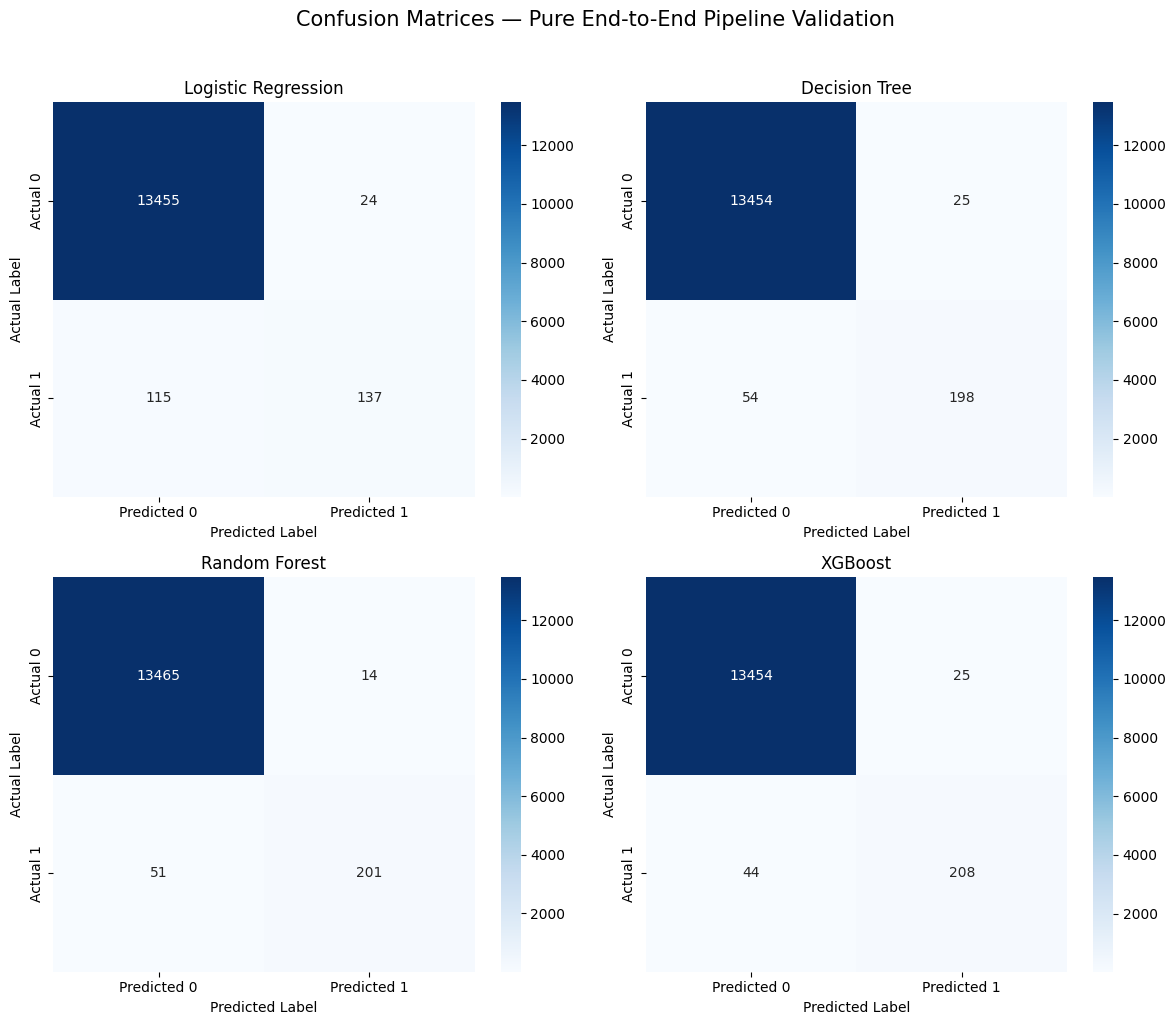

In [275]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):
    y_pred = predictions[name]["y_pred"]
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrices — Pure End-to-End Pipeline Validation", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

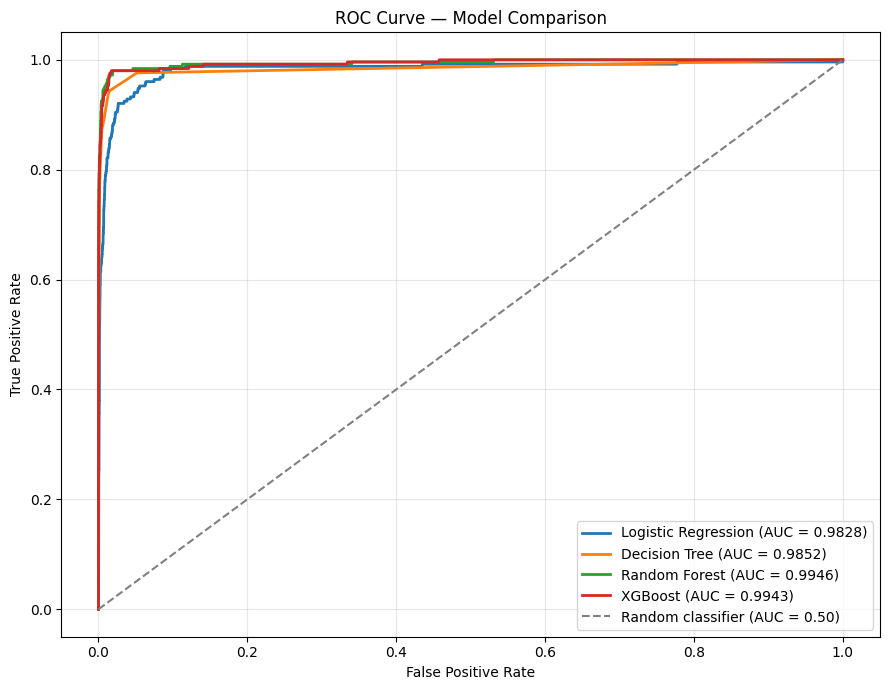

In [276]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 7))

for name, model in models.items():

    y_prob = predictions[name]["y_prob"]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob,
    )

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})",
    )

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier (AUC = 0.50)",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Model Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [277]:
# Serialization of the final pipeline containing all Feature Extraction steps inside
import joblib

joblib.dump(
    {
        "model": final_xgb,
        "numerical_cols": numerical_cols_raw,
        "categorical_cols": categorical_cols_raw
    },
    "xgboost_pipeline.joblib"
)
print("Successfully saved integrated pipeline to xgboost_pipeline.joblib")

Successfully saved integrated pipeline to xgboost_pipeline.joblib


In [278]:
# uvicorn app:app --reload
loan_request = {
  "ID": "ID_257244237466267278",
  "customer_id": 257244,
  "country_id": "Kenya",
  "tbl_loan_id": 237466,
  "lender_id": 267278,
  "loan_type": "Type_1",
  "Total_Amount": 16477.0,
  "Total_Amount_to_Repay": 16642.0,
  "disbursement_date": "2022-08-15",
  "due_date": "2022-08-22",
  "duration": 7,
  "New_versus_Repeat": "Repeat Loan",
  "Amount_Funded_By_Lender": 2436.0,
  "Lender_portion_Funded": 0.147842447047399,
  "Lender_portion_to_be_repaid": 2460.0
}

### Serving the Pipeline with FastAPI

Below is the code for a complete, production-grade `app.py` script. It:
1. Defines a clean Pydantic request schema matching your raw input features.
2. Loads the serialized `xgboost_pipeline.joblib` file safely on startup.
3. Converts raw API requests directly into a single-row Pandas DataFrame and passes them to the pipeline to produce instant default probabilities.

In [279]:
app_code = """
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
import pandas as pd
import joblib
import uvicorn

app = FastAPI(
    title="Credit Risk Assessment Engine",
    description="Serves XGBoost default predictions on raw credit inputs utilizing custom SKLearn transformers.",
    version="1.0.0"
)

# 1. Define the incoming raw loan request schema matching your upstream dataset structures
class LoanRequest(BaseModel):
    id: str = Field(..., alias="ID")
    customer_id: int
    country_id: str
    tbl_loan_id: int
    lender_id: int
    loan_type: str
    total_amount: float = Field(..., alias="Total_Amount")
    total_amount_to_repay: float = Field(..., alias="Total_Amount_to_Repay")
    disbursement_date: str
    due_date: str
    duration: int
    new_versus_repeat: str = Field(..., alias="New_versus_Repeat")
    amount_funded_by_lender: float = Field(..., alias="Amount_Funded_By_Lender")
    lender_portion_funded: float = Field(..., alias="Lender_portion_Funded")
    lender_portion_to_be_repaid: float = Field(..., alias="Lender_portion_to_be_repaid")

    class Config:
        populate_by_name = True

# 2. Load the integrated pipeline containing the model on startup
try:
    artifacts = joblib.load("xgboost_pipeline.joblib")
    model_pipeline = artifacts["model"]
    print("Integrated modeling pipeline successfully loaded.")
except Exception as e:
    raise RuntimeError(f"Failed to load modeling pipeline artifact: {str(e)}")

@app.post("/predict")
def predict_credit_risk(payload: LoanRequest):
    try:
        # Convert payload directly to a dictionary structure matching the raw schema
        input_dict = payload.model_dump(by_alias=True)

        # Convert key headers back to lowercase/snake_case to match the exact headers your Pipeline expects
        raw_df = pd.DataFrame([input_dict])
        raw_df.columns = raw_df.columns.str.lower().str.replace(" ", "_", regex=False)
        raw_df.rename(columns={'country_id': 'country'}, inplace=True)

        # Feed the raw dataframe directly into the pipeline
        probability_of_default = float(model_pipeline.predict_proba(raw_df)[0][1])
        prediction = int(model_pipeline.predict(raw_df)[0])

        return {
            "loan_id": payload.id,
            "default_prediction": prediction,
            "probability_of_default": round(probability_of_default, 4),
            "status": "approved" if probability_of_default < 0.5 else "rejected"
        }
    except Exception as e:
        raise HTTPException(status_code=400, detail=f"Prediction generation failed: {str(e)}")

@app.get("/health")
def health_check():
    return {"status": "healthy"}

if __name__ == '__main__':
    uvicorn.run(app, host='0.0.0.0', port=8000)
"""

# with open("app.py", "w") as f:
#     f.write(app_code)

# print("FastAPI app code successfully written to app.py")